# 03 · Aumento de datos

Este notebook muestra el aumento aleatorio que se aplicará durante el entrenamiento de Slim-CNN y ResNet18 siamesa. **No crea archivos duplicados ni cambia las imágenes fuente.** Cada época puede presentar variaciones distintas. Validación y test permanecen sin aumento.

La política usa cambios moderados de orientación, encuadre e iluminación/color. Sirve para reducir dependencia de posición y luz, pero no garantiza mayor precisión: se debe comprobar comparando resultados en el test reservado. Tampoco inventa nuevos fondos; si todas las imágenes tienen fondo blanco, hace falta recolectar imágenes de otros ambientes para demostrar adaptación a esos fondos.


In [1]:
from pathlib import Path
import sys, yaml, random
import matplotlib.pyplot as plt
import torch
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Abre el notebook dentro del repositorio.')
sys.path.insert(0, str(ROOT))
from src.data.classification import image_transforms
SPLITS = ROOT / 'data' / 'splits'
POLICY = yaml.safe_load((ROOT / 'config/augmentation.yaml').read_text(encoding='utf-8'))
print('Política de aumento:', POLICY)
print('Fuente de entrenamiento:', SPLITS / 'train')


Política de aumento: {'enabled': True, 'horizontal_flip': 0.5, 'vertical_flip': 0.5, 'rotation_degrees': 180, 'translation': 0.04, 'scale_min': 0.9, 'scale_max': 1.1, 'color_probability': 0.7, 'brightness': 0.15, 'contrast': 0.15, 'saturation': 0.08, 'hue': 0.02}
Fuente de entrenamiento: /home/gnavarrete/navarrete_tesis/data/splits/train


## Vista previa

En cada fila: imagen original y cuatro versiones aumentadas solo en memoria. La imagen original no se sobrescribe. Ejecuta esta celda varias veces para ver que los cambios son aleatorios.


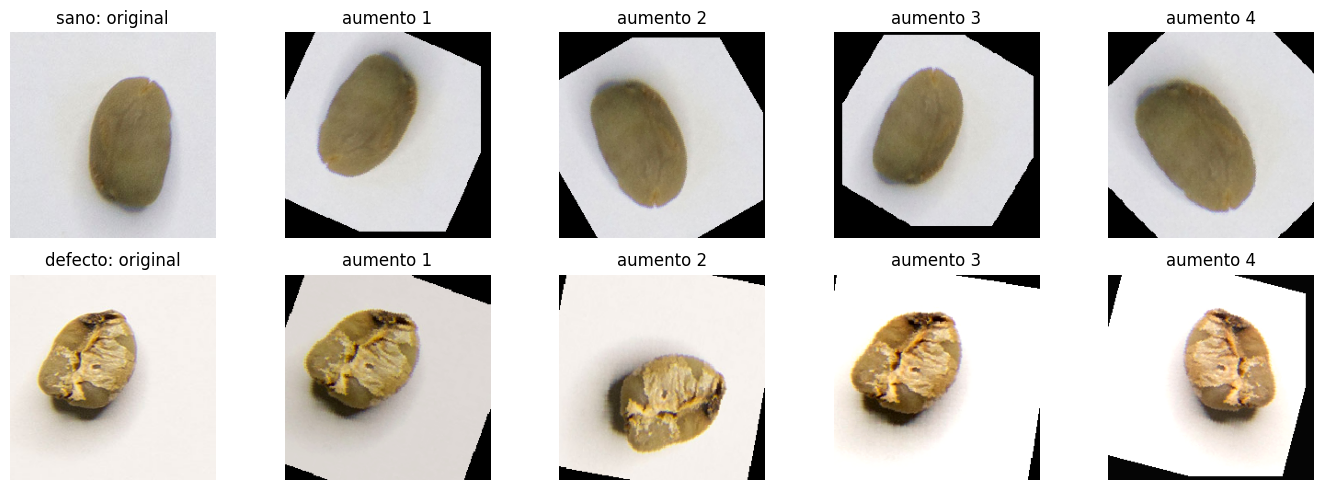

In [3]:
classes = ['sano', 'defecto']
augment = image_transforms(224, training=True)
mean = torch.tensor([.485, .456, .406]).view(3, 1, 1)
std = torch.tensor([.229, .224, .225]).view(3, 1, 1)
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 5))
for row, label in enumerate(classes):
    options = sorted((SPLITS / 'train' / label).glob('*'))
    if not options:
        raise FileNotFoundError(f'No hay imágenes de {label} en {SPLITS / "train"}')
    path = random.choice(options)
    original = Image.open(path).convert('RGB')
    axes[row, 0].imshow(original); axes[row, 0].set_title(f'{label}: original')
    for col in range(1, 5):
        tensor = augment(original).cpu() * std + mean
        view = tensor.clamp(0, 1).permute(1, 2, 0).numpy()
        axes[row, col].imshow(view); axes[row, col].set_title(f'aumento {col}')
    for ax in axes[row]: ax.axis('off')
plt.tight_layout()


## Política y alcance

La puedes ajustar en `config/augmentation.yaml`. `enabled: false` desactiva los cambios para comparar contra una corrida sin aumento. Para una comparación justa, conserva las mismas particiones y semilla, usa el mismo número de épocas y guarda cada corrida con otro nombre de salida/checkpoint. No mires el test para elegir parámetros: úsalo una vez al final.

YOLOv8-cls usa su propio aumento configurado desde el mismo archivo. Para el futuro YOLOv8 de detección, las transformaciones geométricas deben conservar las cajas; Ultralytics lo hace durante entrenamiento. No generaremos imágenes de detección aumentadas sin sus anotaciones transformadas.

### Propuesta

1. Usar este aumento moderado como primera corrida.
2. Comparar validación y luego test con una corrida equivalente sin aumento.
3. Si el objetivo es operar con fondos o cámaras distintos, reservar fotos reales de esos entornos para test externo; el aumento sintético no reemplaza esa diversidad.


## Gráfico de las imágenes que recibe cada modelo

Esta gráfica se puede ejecutar ahora. Resume las imágenes base por clase y estima cuántas presentaciones hace cada arquitectura a lo largo de sus épocas. El aumento de este proyecto se aplica al vuelo: no guarda imágenes nuevas ni cambia el número de presentaciones; genera variaciones aleatorias de las imágenes de entrenamiento. Por eso las barras con y sin aumento tienen igual altura en cantidad. La diferencia que buscamos medir en desempeño aparece en la comparación de validación más abajo, una vez entrenadas ambas versiones.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

index = pd.read_csv(ROOT / 'data/splits/index.csv')
counts = index[index['split'] == 'train'].groupby('class').size().reindex(['sano', 'defecto'], fill_value=0)
epochs = {
    'YOLOv8-cls': int(yaml.safe_load((ROOT / 'config/yolo.yaml').read_text())['epochs']),
    'Slim-CNN': int(yaml.safe_load((ROOT / 'config/slim_cnn.yaml').read_text())['epochs']),
    'ResNet18 siamesa': int(yaml.safe_load((ROOT / 'config/siamese.yaml').read_text())['epochs']),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.bar(ax=axes[0], color=['#398564', '#c87852'])
axes[0].set_title('Imágenes base en train')
axes[0].set_ylabel('Imágenes')
axes[0].set_xlabel('Clase')
axes[0].bar_label(axes[0].containers[0], fmt='%d')
inputs = {name: int(counts.sum()) * n_epochs for name, n_epochs in epochs.items()}
axes[1].bar(list(inputs), list(inputs.values()), color=['#537a9b', '#398564', '#9673a6'])
axes[1].set_title('Presentaciones estimadas durante entrenamiento')
axes[1].set_ylabel('Imágenes vistas (base × épocas)')
axes[1].tick_params(axis='x', rotation=20)
for bars in axes[1].containers:
    axes[1].bar_label(bars, fmt='%.0f')
plt.tight_layout()
print('Aumento activado:', POLICY['enabled'], '| las transformaciones cambian la apariencia, no la cantidad de muestras.')


## Medir si el aumento mejora la validación

El gráfico de barras de abajo compara el mejor resultado de validación de dos entrenamientos reales: uno con `enabled: false` y otro con `enabled: true`. Para cada modelo, mantén iguales las particiones, semilla, épocas y demás ajustes. Cambia únicamente `enabled` y usa carpetas diferentes para conservar ambos resultados.

Ejemplo Slim-CNN: edita `config/augmentation.yaml` a `enabled: false`, ejecuta el primer comando; cámbialo a `true` y ejecuta el segundo. Para la siamesa, reemplaza `slim_cnn` y los nombres de salida por `siamese_resnet18` y `siamese_resnet18_sin_aumento` / `siamese_resnet18_con_aumento`. Para YOLOv8-cls, usa `--model yolov8_cls --run-name yolov8_cls_sin_aumento` y luego `yolov8_cls_con_aumento`.

```bash
python -m src.train --model slim_cnn --output checkpoints/slim_cnn_sin_aumento
python -m src.train --model slim_cnn --output checkpoints/slim_cnn_con_aumento
```

Luego ejecuta la celda siguiente. La métrica siamesa mide verificación de pares, así que sus valores se interpretan dentro de ese modelo y no como equivalentes a la clasificación de imágenes. El test reservado debe usarse después de elegir la configuración, para una evaluación final.


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

RUNS = {
    'YOLOv8-cls': {'Sin aumento': ROOT/'checkpoints/yolov8_cls_sin_aumento/results.csv', 'Con aumento': ROOT/'checkpoints/yolov8_cls_con_aumento/results.csv'},
    'Slim-CNN': {'Sin aumento': ROOT/'checkpoints/slim_cnn_sin_aumento/history.json', 'Con aumento': ROOT/'checkpoints/slim_cnn_con_aumento/history.json'},
    'ResNet18 siamesa': {'Sin aumento': ROOT/'checkpoints/siamese_resnet18_sin_aumento/history.json', 'Con aumento': ROOT/'checkpoints/siamese_resnet18_con_aumento/history.json'},
}
def best_score(model, path):
    if model == 'YOLOv8-cls':
        hist = pd.read_csv(path)
        col = next(c for c in hist.columns if c.strip().lower() == 'metrics/accuracy_top1')
        return float(hist[col].max())
    hist = json.loads(path.read_text(encoding='utf-8'))
    best = min(hist, key=lambda row: row['val_loss'])
    key = 'val_pair_accuracy' if model == 'ResNet18 siamesa' else 'val_accuracy'
    return float(best[key])

rows, missing = [], []
for model, paths in RUNS.items():
    if not all(path.is_file() for path in paths.values()):
        missing.extend(str(path) for path in paths.values() if not path.is_file())
        continue
    base, augmented = (best_score(model, paths[label]) for label in ('Sin aumento', 'Con aumento'))
    rows.append({'modelo': model, 'Sin aumento': base, 'Con aumento': augmented,
                 'cambio (pp)': (augmented-base)*100})
if rows:
    result = pd.DataFrame(rows)
    display(result)
    fig, axes = plt.subplots(1, len(rows), figsize=(5*len(rows), 4), squeeze=False)
    for ax, row in zip(axes.flat, rows):
        bars = ax.bar(['Sin aumento', 'Con aumento'], [row['Sin aumento']*100, row['Con aumento']*100], color=['#8c9aa8', '#398564'])
        ax.set_ylim(0, 100); ax.set_ylabel('Mejor validación (%)')
        ax.set_title(f"{row['modelo']}\nΔ {row['cambio (pp)']:+.2f} pp")
        ax.bar_label(bars, fmt='%.1f%%')
    plt.tight_layout()
else:
    print('Este gráfico requiere entrenar ambas versiones (con y sin aumento) de al menos un modelo.')
if missing:
    print('Historiales aún no encontrados:')
    for path in missing: print('-', path)
